In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

In [2]:
df= pd.read_csv('insurance.csv')

In [3]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [4]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
#EDA

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [7]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [8]:
df.isnull()

,age,sex,bmi,children,smoker,region,charges
0,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...
1333,False,False,False,False,False,False,False
1334,False,False,False,False,False,False,False
1335,False,False,False,False,False,False,False
1336,False,False,False,False,False,False,False


In [9]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [10]:
numaric_col=['age','bmi','children','charges']

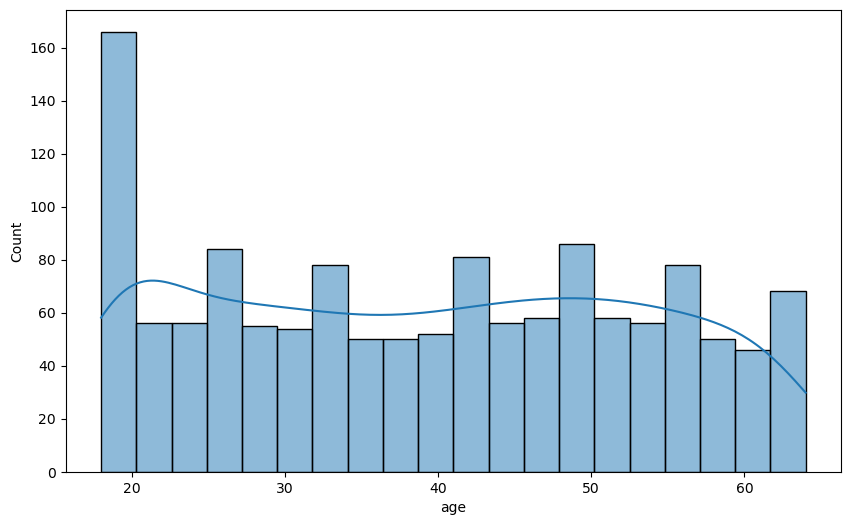

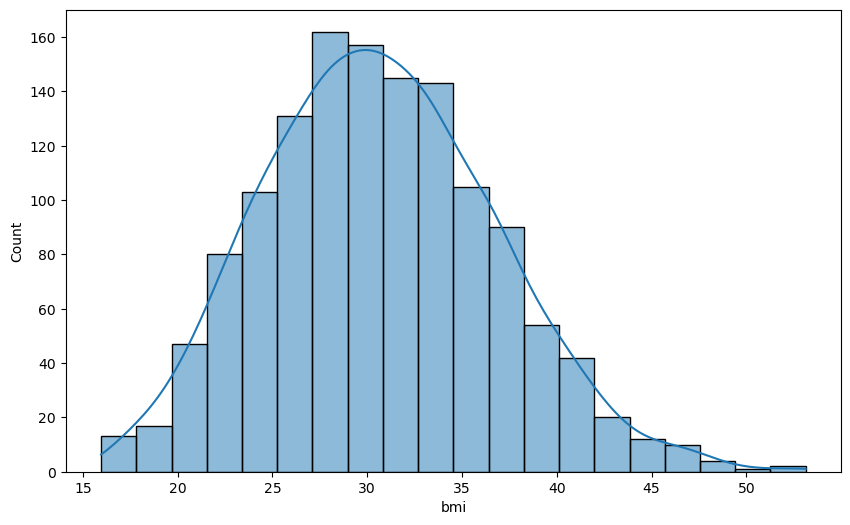

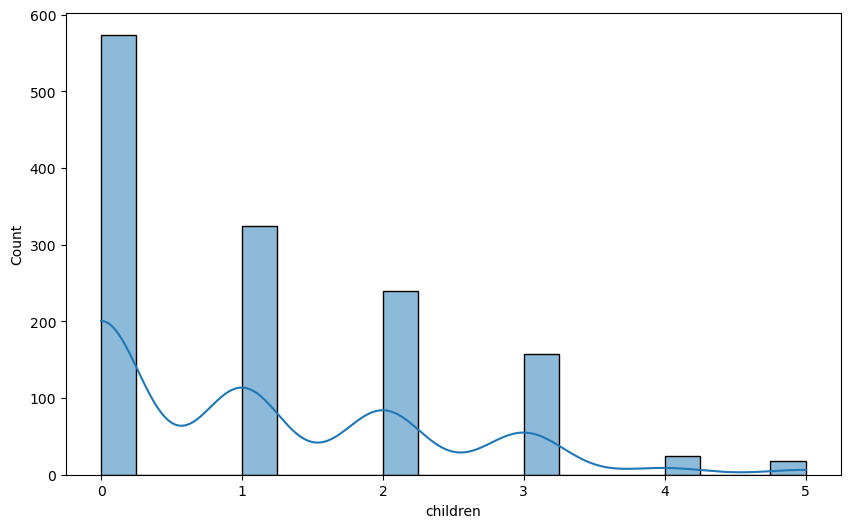

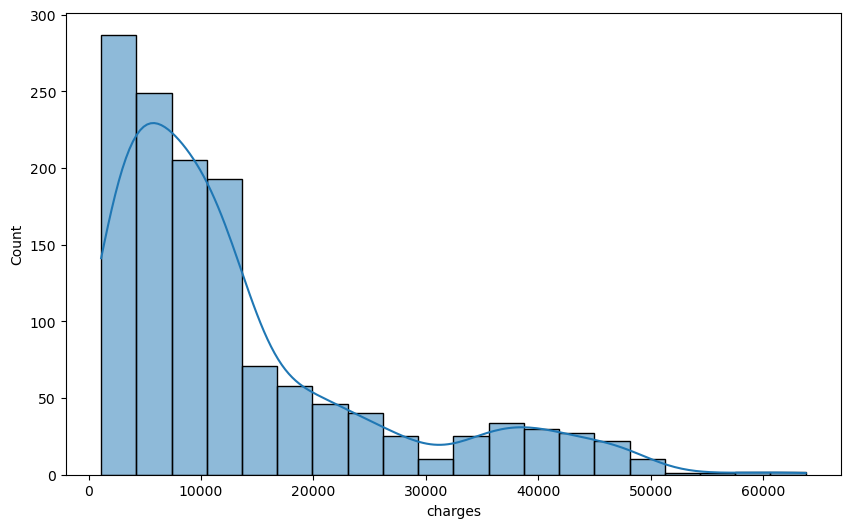

In [11]:
for cal in numaric_col :
    plt.figure(figsize=(10,6))
    sns.histplot(data=df[cal],kde=True,bins=20)
    plt.show()

<Axes: xlabel='children', ylabel='count'>

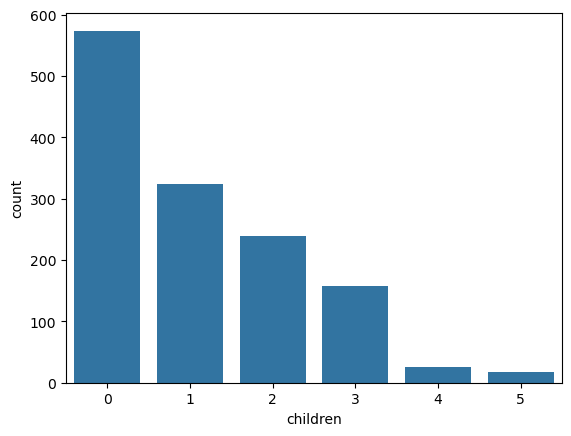

In [12]:
sns.countplot(x=df['children'])

<Axes: xlabel='sex', ylabel='count'>

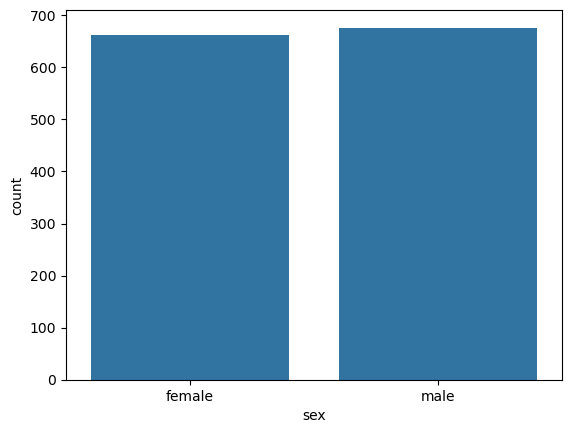

In [13]:
sns.countplot(x=df['sex'])

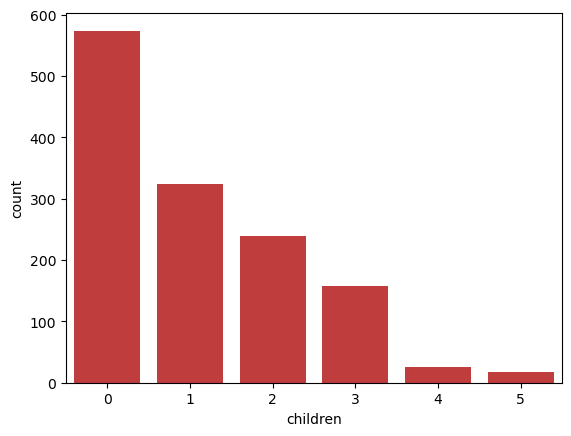

In [14]:
for cal in numaric_col:
   sns.countplot(x=df['children'])

<Axes: >

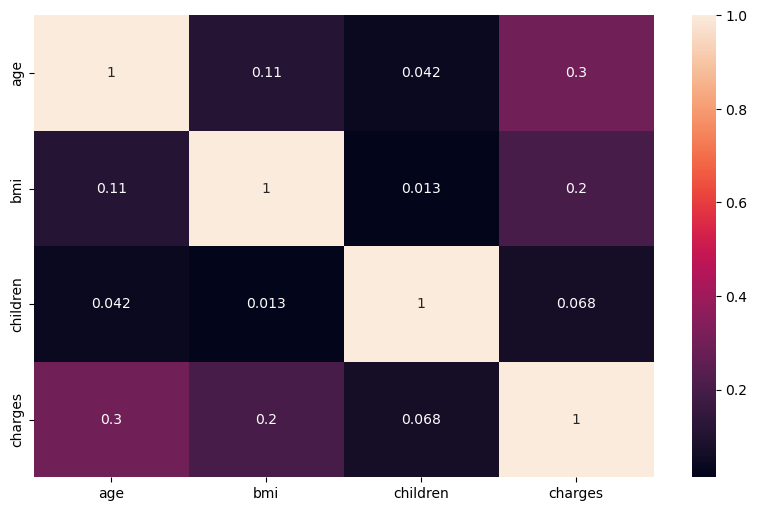

In [15]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)

DATA CLEANING AND PREPROCESING

In [16]:
df_copy=df.copy()


In [17]:
df_copy.shape

(1338, 7)

In [18]:
df_copy.drop_duplicates(inplace=True)

In [19]:
df_copy.shape

(1337, 7)

converting objects( string ) in to numeric data


In [20]:
df_copy['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [21]:
df_copy['sex']=df_copy['sex'].map({"male":0,"female":1})

In [22]:
df_copy.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [23]:
df_copy['smoker']=df_copy['smoker'].map({"no":0,"yes":1})

In [24]:
df_copy.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [25]:
df_copy.rename(columns={
    "sex":"is_female",
    "smoker":"is_smoker"
},inplace=True)

In [26]:
df_copy

,age,is_female,bmi,children,is_smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,northwest,10600.54830
1334,18,1,31.920,0,0,northeast,2205.98080
1335,18,1,36.850,0,0,southeast,1629.83350
1336,21,1,25.800,0,0,southwest,2007.94500


In [27]:
df_copy=pd.get_dummies(df_copy, columns=['region'], drop_first=True)

In [28]:
df_copy=df_copy.astype(int)

In [29]:
df_copy

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,0,1
1,18,0,33,1,0,1725,0,1,0
2,28,0,33,3,0,4449,0,1,0
3,33,0,22,0,0,21984,1,0,0
4,32,0,28,0,0,3866,1,0,0
...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,1,0,0
1334,18,1,31,0,0,2205,0,0,0
1335,18,1,36,0,0,1629,0,1,0
1336,21,1,25,0,0,2007,0,0,1


feature engineering 


In [30]:
df_copy['bmi_category']=pd.cut(
    df_copy['bmi'],
    bins=[0,18.5,24.9,29.9,float('inf')],
    labels=['underweight','normal','overweight','obses']
)

In [31]:
df_copy

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27,0,1,16884,0,0,1,overweight
1,18,0,33,1,0,1725,0,1,0,obses
2,28,0,33,3,0,4449,0,1,0,obses
3,33,0,22,0,0,21984,1,0,0,normal
4,32,0,28,0,0,3866,1,0,0,overweight
...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,1,0,0,obses
1334,18,1,31,0,0,2205,0,0,0,obses
1335,18,1,36,0,0,1629,0,1,0,obses
1336,21,1,25,0,0,2007,0,0,1,overweight


In [32]:
df_copy=pd.get_dummies(df_copy, columns=['bmi_category'])

In [33]:
df_copy

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_underweight,bmi_category_normal,bmi_category_overweight,bmi_category_obses
0,19,1,27,0,1,16884,0,0,1,False,False,True,False
1,18,0,33,1,0,1725,0,1,0,False,False,False,True
2,28,0,33,3,0,4449,0,1,0,False,False,False,True
3,33,0,22,0,0,21984,1,0,0,False,True,False,False
4,32,0,28,0,0,3866,1,0,0,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,1,0,0,False,False,False,True
1334,18,1,31,0,0,2205,0,0,0,False,False,False,True
1335,18,1,36,0,0,1629,0,1,0,False,False,False,True
1336,21,1,25,0,0,2007,0,0,1,False,False,True,False


In [34]:
df_copy

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_underweight,bmi_category_normal,bmi_category_overweight,bmi_category_obses
0,19,1,27,0,1,16884,0,0,1,False,False,True,False
1,18,0,33,1,0,1725,0,1,0,False,False,False,True
2,28,0,33,3,0,4449,0,1,0,False,False,False,True
3,33,0,22,0,0,21984,1,0,0,False,True,False,False
4,32,0,28,0,0,3866,1,0,0,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,1,0,0,False,False,False,True
1334,18,1,31,0,0,2205,0,0,0,False,False,False,True
1335,18,1,36,0,0,1629,0,1,0,False,False,False,True
1336,21,1,25,0,0,2007,0,0,1,False,False,True,False


In [35]:
df_copy=df_copy.astype(int)

In [36]:
df_copy

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_underweight,bmi_category_normal,bmi_category_overweight,bmi_category_obses
0,19,1,27,0,1,16884,0,0,1,0,0,1,0
1,18,0,33,1,0,1725,0,1,0,0,0,0,1
2,28,0,33,3,0,4449,0,1,0,0,0,0,1
3,33,0,22,0,0,21984,1,0,0,0,1,0,0
4,32,0,28,0,0,3866,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,1,0,0,0,0,0,1
1334,18,1,31,0,0,2205,0,0,0,0,0,0,1
1335,18,1,36,0,0,1629,0,1,0,0,0,0,1
1336,21,1,25,0,0,2007,0,0,1,0,0,1,0


In [37]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [38]:
from sklearn.preprocessing import StandardScaler
col=['age','bmi','children']
scaler=StandardScaler()
df_copy[col]=scaler.fit_transform(df_copy[col])

In [39]:

df_copy.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_underweight,bmi_category_normal,bmi_category_overweight,bmi_category_obses
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,1,0,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725,0,1,0,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,4449,0,1,0,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,1,0,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,1,0,0,0,0,1,0


In [40]:
df_copy.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_underweight', 'bmi_category_normal',
       'bmi_category_overweight', 'bmi_category_obses'],
      dtype='object')

In [41]:
from scipy.stats import pearsonr
select_feature=[
    'age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_underweight', 'bmi_category_normal',
       'bmi_category_overweight', 'bmi_category_obses'
]
correlations={
    feature: pearsonr(df_copy[feature],df_copy['charges'])[0]
    for feature in select_feature
}
correlations_df=pd.DataFrame(list(correlations.items()),columns=['feature','Pearson Correlation'])
correlations_df.sort_values(by='Pearson Correlation',ascending=False)


,feature,Pearson Correlation
5,charges,1.000000
4,is_smoker,0.787234
0,age,0.298309
12,bmi_category_obses,0.200348
2,bmi,0.196236
7,region_southeast,0.073577
3,children,0.067390
6,region_northwest,-0.038695
8,region_southwest,-0.043637
9,bmi_category_underweight,-0.050599


In [42]:
from scipy.stats import chi2_contingency
import pandas as pd

alpha = 0.05

df_copy['charges_bin'] = pd.qcut(df_copy['charges'], q=4, labels=False)
chi2_results = {}

for col in select_feature:
    contingency = pd.crosstab(df_copy[col], df_copy['charges_bin'])
    chi2_stat, p_val, dof, expected = chi2_contingency(contingency)
    
    decision = 'Reject Null (Keep Feature)' if p_val < alpha else 'Accept Null (Drop Feature)'
    
    chi2_results[col] = {
        'chi2_statistic': chi2_stat,
        'pvalue': p_val,
        'Decision': decision
    }
    chi2_df=pd.DataFrame(chi2_results).T
    chi2_df=chi2_df.sort_values(by='pvalue')
    chi2_df


In [43]:
chi2_df

,chi2_statistic,pvalue,Decision
age,1509.13025,0.0,Reject Null (Keep Feature)
is_smoker,848.219178,0.0,Reject Null (Keep Feature)
children,138.659313,0.0,Reject Null (Keep Feature)
region_southeast,15.998167,0.001135,Reject Null (Keep Feature)
is_female,10.258784,0.01649,Reject Null (Keep Feature)
bmi,144.758888,0.017278,Reject Null (Keep Feature)
charges,4011.0,0.033723,Reject Null (Keep Feature)
bmi_category_obses,8.515711,0.036473,Reject Null (Keep Feature)
region_southwest,5.091893,0.165191,Accept Null (Drop Feature)
bmi_category_overweight,4.25149,0.235557,Accept Null (Drop Feature)


In [44]:
df_copy.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_underweight', 'bmi_category_normal',
       'bmi_category_overweight', 'bmi_category_obses', 'charges_bin'],
      dtype='object')

In [45]:
final=df_copy[['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_southwest','bmi_category_obses']]
final

,age,is_female,bmi,children,is_smoker,charges,region_southwest,bmi_category_obses
0,-1.440418,1,-0.517949,-0.909234,1,16884,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725,0,1
2,-0.799350,0,0.462463,1.580143,0,4449,0,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,0
...,...,...,...,...,...,...,...,...
1333,0.767704,0,-0.027743,1.580143,0,10600,0,1
1334,-1.511647,1,0.135659,-0.909234,0,2205,0,1
1335,-1.511647,1,0.952670,-0.909234,0,1629,0,1
1336,-1.297958,1,-0.844753,-0.909234,0,2007,1,0


In [46]:
from sklearn.model_selection import train_test_split

In [47]:
X=final.drop('charges',axis=1)
Y=final['charges']

In [48]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.20,random_state=42)

In [49]:
from sklearn.linear_model import LinearRegression

In [50]:
model=LinearRegression()
model.fit(X_train,Y_train)

LinearRegression()

In [51]:
y_pred=model.predict(X_test)

In [54]:
from sklearn.metrics import r2_score
r2=r2_score(Y_test,y_pred)
r2
n=X_test.shape[0]
p=X_test.shape[1]
adj_r2=1-((1-r2)*(n-1)/(n-p-1))
adj_r2


0.7989537776214413